In [31]:
import numpy as np
import matplotlib.pyplot as plt
import PyMPDATA as mp

In [32]:
from PyMPDATA import \
  ScalarField,\
  VectorField,\
  Options,\
  boundary_conditions as bc

$$
  \psi_0 = e^{-x^2}
$$
$$
C = u\frac{\Delta t}{\Delta x}
$$

In [33]:
options = Options(n_iters=4, infinite_gauge=True,
                  nonoscillatory=True, third_order_terms=True)
common = {
  'halo': options.n_halo,
  'boundary_conditions': (bc.Periodic(),),
}

psi = ScalarField(**common, data=(
   np.exp(-(x:=np.linspace(-2,8,40))**2)
))
C= VectorField(**common, data=(
   np.full(x.size + 1, 1./4),
))

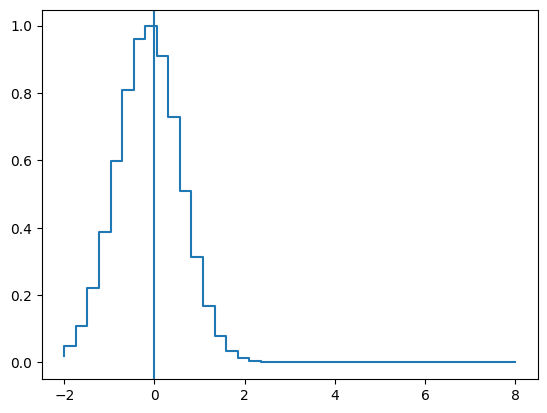

In [34]:
plt.step(x, psi.get())
plt.axvline(0)

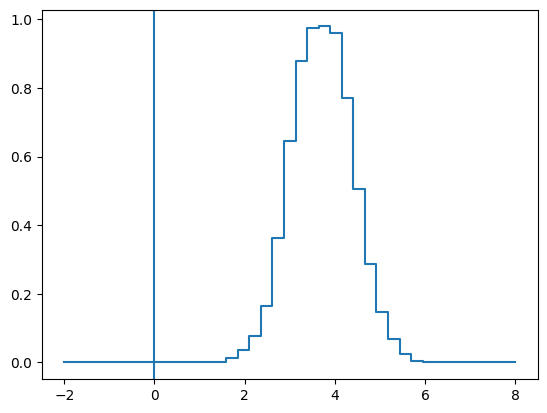

In [35]:
from PyMPDATA import Stepper, Solver

solver = Solver(advector=C, advectee=psi,
                stepper=Stepper(n_dims = 1, options=options))

solver.advance(60)
plt.step(x, psi.get())
plt.axvline(0)